# Schritt 3: EDP/NDP Real-World Graphs

Dieses reine Auswertungsnotebook fasst die Pilot5- und die vollständigen 1000-Run-Reihen für ATT-MPLS, Cogentco und Oteglobe zusammen.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_step3_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        root = candidate / "schritt3_knoten_disjunkte_pfade"
        if root.exists():
            return root
        if candidate.name == "schritt3_knoten_disjunkte_pfade":
            return candidate
    raise FileNotFoundError("schritt3_knoten_disjunkte_pfade wurde nicht gefunden")


STEP3_ROOT = find_step3_root()
SRC_ROOT = STEP3_ROOT / "src"
COLORS = {"EDP": "#4C78A8", "NDP": "#F58518"}
MARKERS = {"EDP": "o", "NDP": "s"}
PLOT_ROOT = STEP3_ROOT / "evaluation" / "output" / "ndp_edp_real_world_runs1000"
PLOT_ROOT.mkdir(parents=True, exist_ok=True)

TOPOLOGIES = [
    {"name": "attmpls", "title": "ATT-MPLS (n=25)", "size": (25, 56)},
    {"name": "cogentco", "title": "Cogentco (n=197)", "size": (197, 243)},
    {"name": "oteglobe", "title": "Oteglobe (n=93)", "size": (93, 103)},
]
print("Gemeinsamer Plot-Ordner:", PLOT_ROOT)


Gemeinsamer Plot-Ordner: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000


## Pilot5- und 1000-Run-Reihen laden und kontrollieren

In [2]:
def load_real_world_series(series):
    frames = []
    expected_rows = 5 if series == "pilot5" else 1000
    for topology in TOPOLOGIES:
        for model in ["random", "clustered"]:
            input_dir = SRC_ROOT / f"output_ndp_edp_zoo_{model}_{topology['name']}_{series}"
            csv_files = sorted(input_dir.glob("*.csv"))
            expected_files = 6 if series == "pilot5" else (20 if model == "random" else 14)
            assert len(csv_files) == expected_files, (
                f"{input_dir}: erwartet {expected_files} CSVs, gefunden {len(csv_files)}"
            )
            for csv_path in csv_files:
                frame = pd.read_csv(csv_path)
                assert len(frame) == expected_rows
                assert frame["rep"].nunique() == expected_rows
                assert set(frame["graphType"]) == {"graphml"}
                assert set(frame["graphName"]) == {topology["name"]}
                assert set(zip(frame["nrNodes"], frame["nrEdges"])) == {topology["size"]}
                frame["series"] = series
                frames.append(frame)
    return pd.concat(frames, ignore_index=True)


raw_results = pd.concat(
    [load_real_world_series("pilot5"), load_real_world_series("runs1000")],
    ignore_index=True,
)
display(raw_results.groupby(["series", "graphName", "failureModel", "failureType"]).size().unstack(fill_value=0))


failureType                       link   node
series   graphName failureModel              
pilot5   attmpls   clustered        15     15
                   random           15     15
         cogentco  clustered        15     15
                   random           15     15
         oteglobe  clustered        15     15
                   random           15     15
runs1000 attmpls   clustered      7000   7000
                   random        10000  10000
         cogentco  clustered      7000   7000
                   random        10000  10000
         oteglobe  clustered      7000   7000
                   random        10000  10000

## Kennzahlen berechnen

In [3]:
summary_rows = []
group_columns = ["series", "graphName", "failureModel", "failureType", "failFactor", "failureStart"]
for keys, frame in raw_results.groupby(group_columns, dropna=False):
    series, graph_name, model, failure_type, fail_factor, failure_start = keys
    x_value = fail_factor if model == "random" else failure_start
    for algorithm in ["EDP", "NDP"]:
        hops = frame[f"hops{algorithm}"]
        successful = frame[hops != -1]
        summary_rows.append({
            "series": series,
            "graphName": graph_name,
            "failureModel": model,
            "failureType": failure_type,
            "xValue": x_value,
            "algorithm": algorithm,
            "resilience": (hops != -1).mean(),
            "meanHopsSuccessful": successful[f"hops{algorithm}"].mean(),
            "meanFailures": frame["nrFails"].mean(),
        })

summary = pd.DataFrame(summary_rows)
summary.head(12)


,series,graphName,failureModel,failureType,xValue,algorithm,resilience,meanHopsSuccessful,meanFailures
0,pilot5,attmpls,clustered,link,0.3,EDP,1.0,2.800000,0.0
1,pilot5,attmpls,clustered,link,0.3,NDP,1.0,2.800000,0.0
2,pilot5,attmpls,clustered,link,0.6,EDP,0.4,3.000000,3.2
3,pilot5,attmpls,clustered,link,0.6,NDP,0.6,5.000000,3.2
4,pilot5,attmpls,clustered,link,0.9,EDP,0.0,NaN,13.8
5,pilot5,attmpls,clustered,link,0.9,NDP,0.0,NaN,13.8
6,pilot5,attmpls,clustered,node,0.3,EDP,1.0,2.800000,0.0
7,pilot5,attmpls,clustered,node,0.3,NDP,1.0,2.800000,0.0
8,pilot5,attmpls,clustered,node,0.6,EDP,0.6,2.666667,2.6
9,pilot5,attmpls,clustered,node,0.6,NDP,0.6,2.666667,2.6


## Pilot5- und 1000-Run-Vergleichsplots

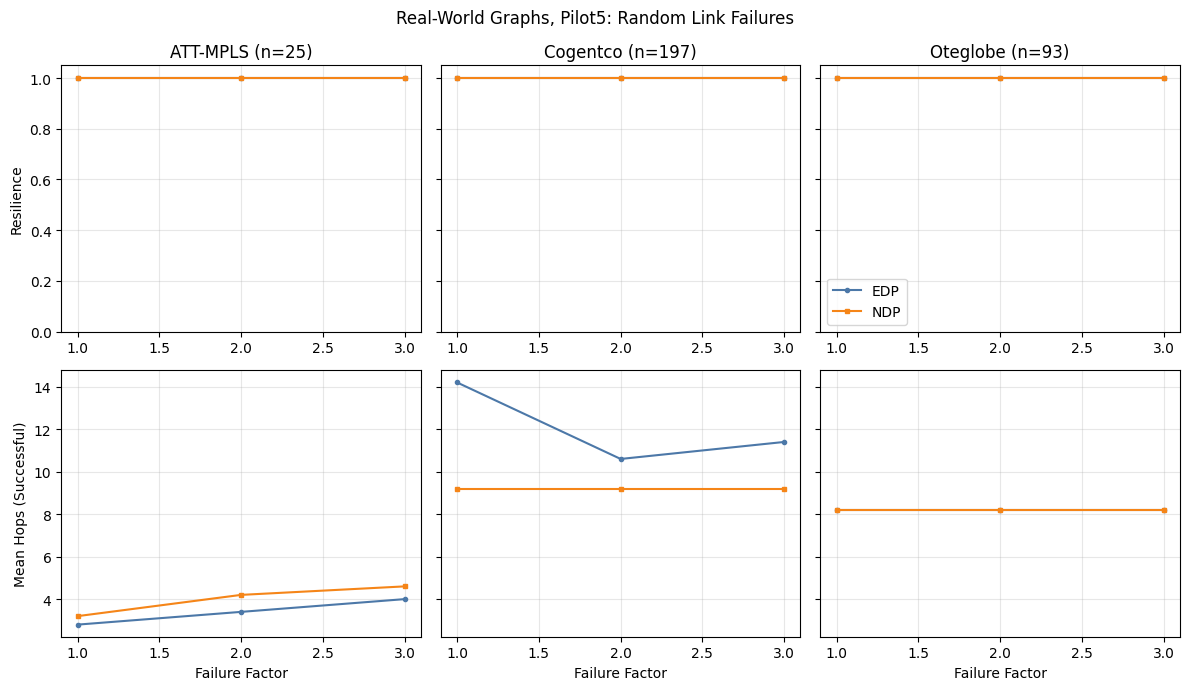

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_pilot5_random_link.png


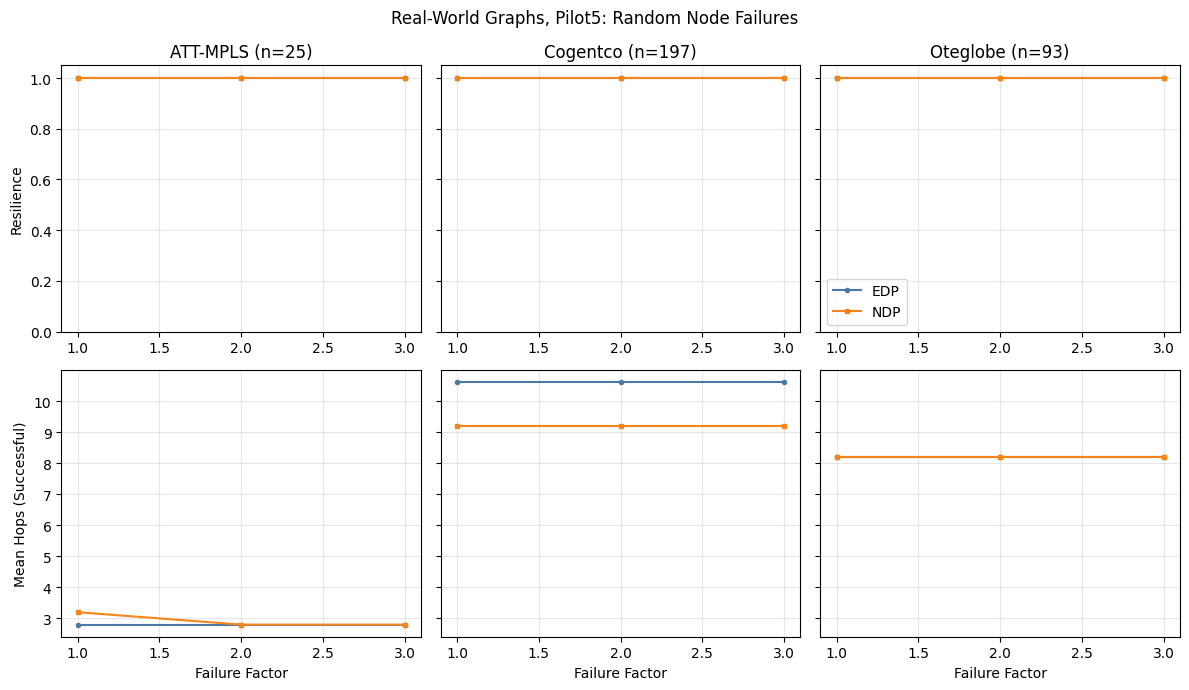

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_pilot5_random_node.png


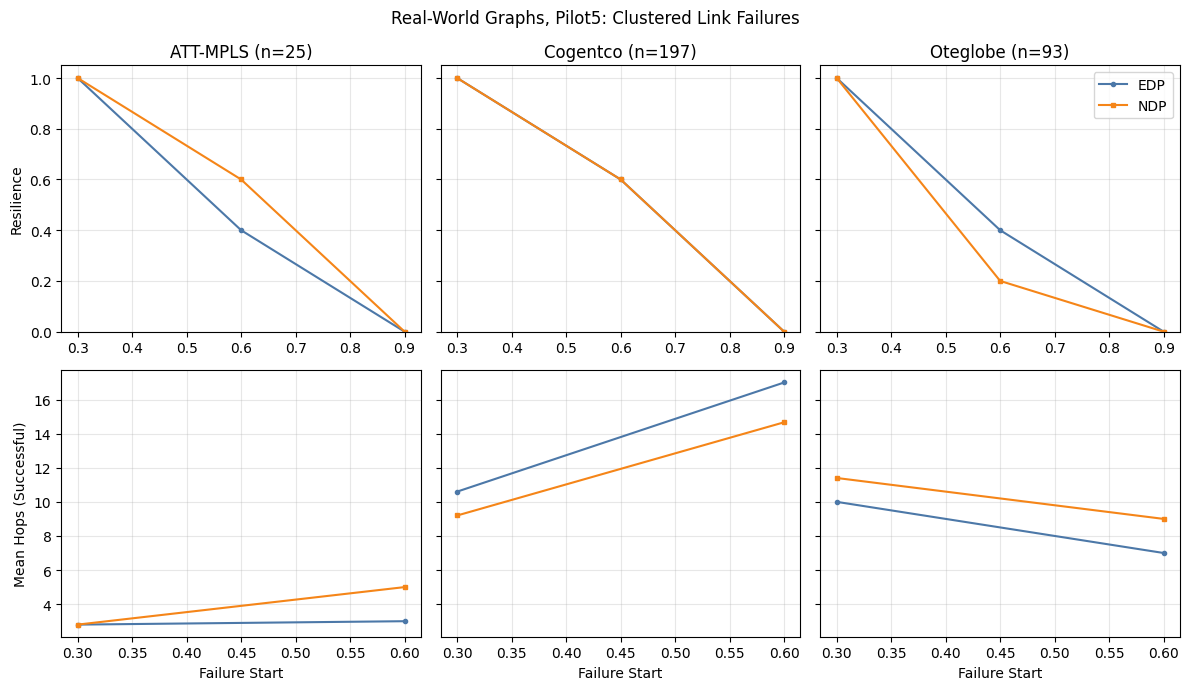

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_pilot5_clustered_link.png


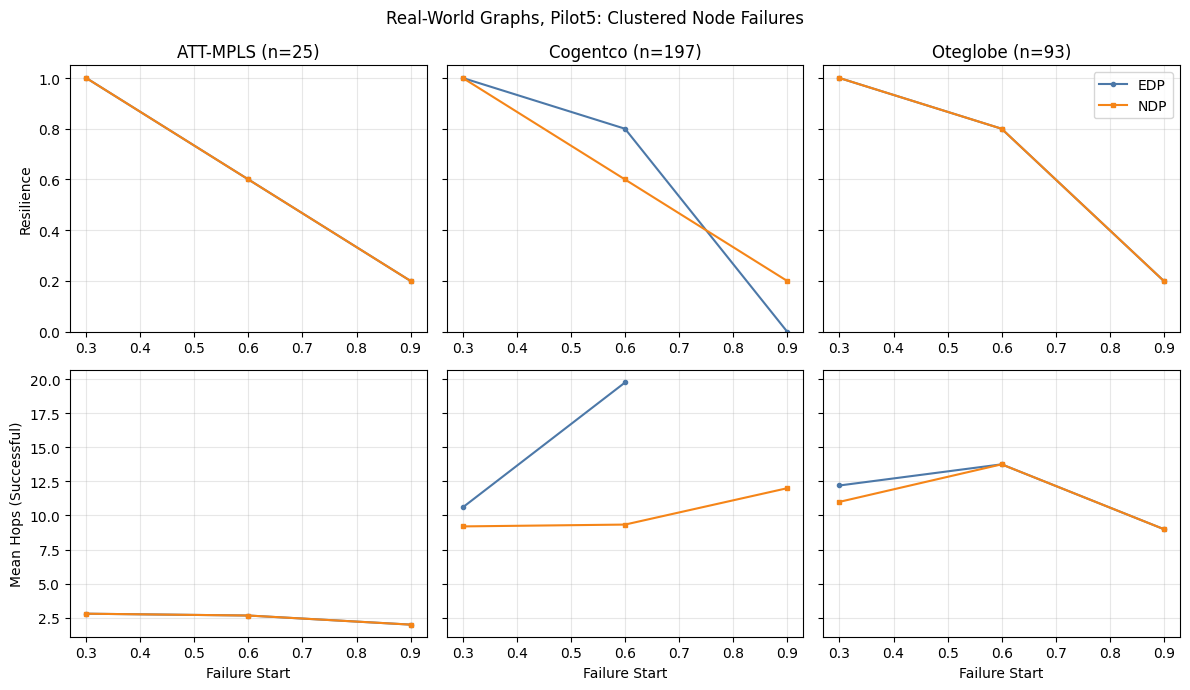

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_pilot5_clustered_node.png


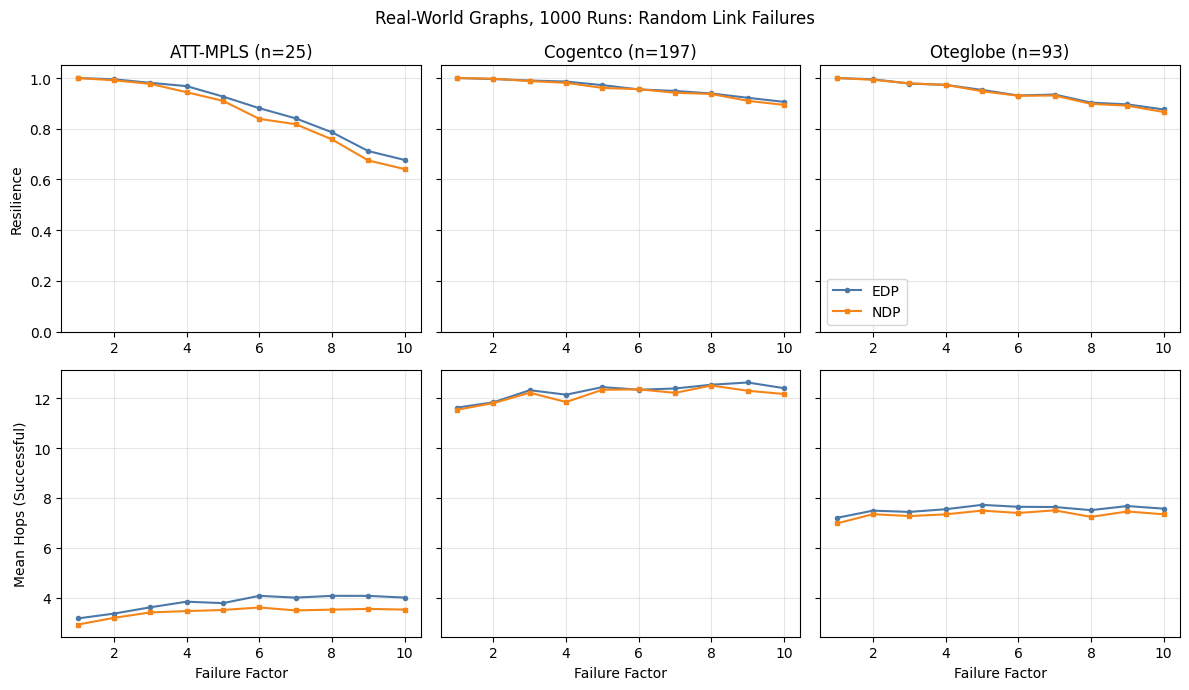

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_runs1000_random_link.png


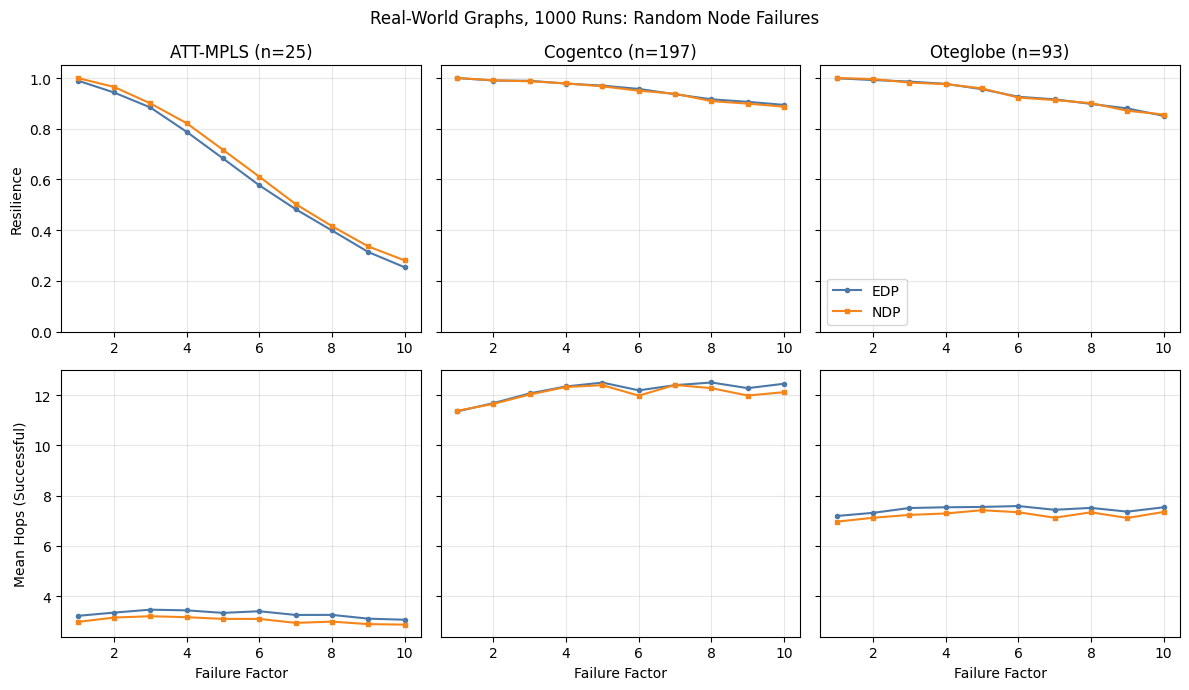

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_runs1000_random_node.png


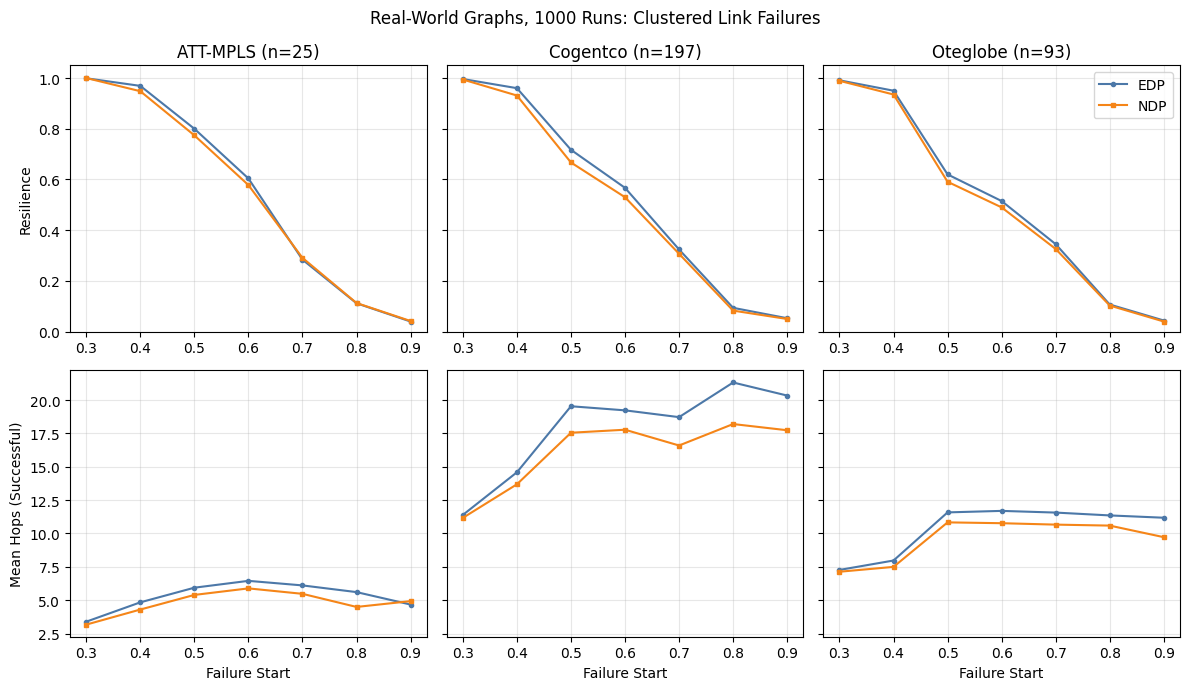

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_runs1000_clustered_link.png


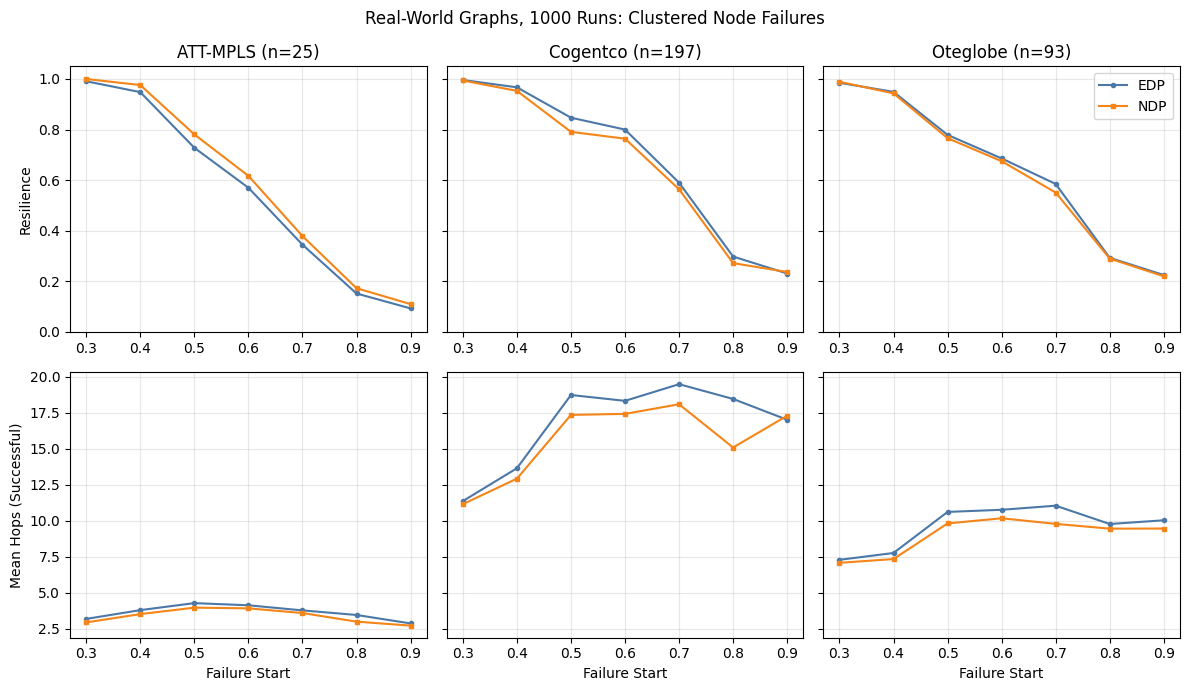

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_real_world_runs1000\ndp_edp_real_world_runs1000_clustered_node.png


In [4]:
def plot_real_world_grid(series, model, failure_type):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey="row")
    x_label = "Failure Factor" if model == "random" else "Failure Start"
    for column, topology in enumerate(TOPOLOGIES):
        subset = summary[
            (summary["series"] == series)
            & (summary["graphName"] == topology["name"])
            & (summary["failureModel"] == model)
            & (summary["failureType"] == failure_type)
        ]
        for algorithm in ["EDP", "NDP"]:
            line = subset[subset["algorithm"] == algorithm]
            axes[0, column].plot(line["xValue"], line["resilience"], marker=MARKERS[algorithm], color=COLORS[algorithm], label=algorithm, markersize=3)
            axes[1, column].plot(line["xValue"], line["meanHopsSuccessful"], marker=MARKERS[algorithm], color=COLORS[algorithm], label=algorithm, markersize=3)
        axes[0, column].set_title(topology["title"])
        axes[0, column].set_ylim(0, 1.05)
        axes[0, column].grid(alpha=0.3)
        axes[1, column].grid(alpha=0.3)
        axes[1, column].set_xlabel(x_label)
    axes[0, 0].set_ylabel("Resilience")
    axes[1, 0].set_ylabel("Mean Hops (Successful)")
    axes[0, 2].legend()
    series_title = "Pilot5" if series == "pilot5" else "1000 Runs"
    fig.suptitle(f"Real-World Graphs, {series_title}: {model.title()} {failure_type.title()} Failures")
    plt.tight_layout()
    output_path = PLOT_ROOT / f"ndp_edp_real_world_{series}_{model}_{failure_type}.png"
    plt.savefig(output_path, dpi=180)
    plt.show()
    print("Plot:", output_path)


for series in ["pilot5", "runs1000"]:
    for model in ["random", "clustered"]:
        for failure_type in ["link", "node"]:
            plot_real_world_grid(series, model, failure_type)


## Tatsächliche mittlere Ausfallzahlen und Resilience

In [5]:
summary[
    ["series", "graphName", "failureModel", "failureType", "xValue", "algorithm", "meanFailures", "resilience"]
].drop_duplicates(["series", "graphName", "failureModel", "failureType", "xValue", "algorithm"])


,series,graphName,failureModel,failureType,xValue,algorithm,meanFailures,resilience
0,pilot5,attmpls,clustered,link,0.3,EDP,0.000,1.000
1,pilot5,attmpls,clustered,link,0.3,NDP,0.000,1.000
2,pilot5,attmpls,clustered,link,0.6,EDP,3.200,0.400
3,pilot5,attmpls,clustered,link,0.6,NDP,3.200,0.600
4,pilot5,attmpls,clustered,link,0.9,EDP,13.800,0.000
...,...,...,...,...,...,...,...,...
271,runs1000,oteglobe,random,node,8.0,NDP,3.488,0.901
272,runs1000,oteglobe,random,node,9.0,EDP,3.924,0.880
273,runs1000,oteglobe,random,node,9.0,NDP,3.924,0.871
274,runs1000,oteglobe,random,node,10.0,EDP,4.360,0.851
